# Chiến Lược Giữ Chân Khách Hàng & Kế Hoạch Hành Động

**Mục tiêu:**
1. **Tổng hợp chéo Cohort + RFM:** Khắc họa các đặc tính vận hành cốt lõi của mô hình bán buôn/bán sỉ (B2B Wholesale), bao gồm phân rã Pareto và độ tập trung doanh thu.
2. **Xây dựng CRM Action Playbook:** Thiết kế khung chiến lược tương tác chuyên biệt cho 10 phân khúc khách hàng và nhóm Zero Net Spend.
3. **Thiết kế Khung thử nghiệm A/B Testing:** Xác lập kế hoạch thực nghiệm khoa học nhằm tìm thời điểm can thiệp kích hoạt tối ưu (Ngày 45 vs Ngày 75) dựa trên tỷ lệ tự mua lại nền phẳng 15%–18% và nhóm đối chứng (Holdout Group).
4. **Mô hình hóa Tác động Doanh thu & Tài chính:** Lượng hóa doanh thu tăng thêm khi cải thiện retention (+2.0 điểm % retention Tháng 1 mang lại ~£32.8k doanh thu gộp ngay trong Tháng 1).
5. **Khuyến nghị chiến lược B2B:** Đề xuất chính sách chiết khấu bậc thang (Volume Rebates), quản trị khách hàng trọng điểm (KAM), và chiến dịch đặt cọc sớm mùa lễ hội (Q4 Early Bird Ordering).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Thiết lập giao diện biểu đồ chuẩn
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# Nạp bảng phân khúc RFM đã xử lý (hỗ trợ cả chạy từ root hoặc từ thư mục notebooks/)
rfm_path = "../data/processed/rfm_segmented.parquet" if os.path.exists("../data/processed/rfm_segmented.parquet") else "data/processed/rfm_segmented.parquet"
rfm = pd.read_parquet(rfm_path)
print("Đã tải xong bảng RFM Segmented: " + str(len(rfm)) + " khách hàng!")


Đã tải xong bảng RFM Segmented: 4334 khách hàng!


## 1. Tổng Hợp Đặc Thù Vận Hành B2B Wholesale: Phân Tích Độ Lệch Pareto
Trong mô hình bán sỉ (B2B Wholesale), doanh thu công ty phụ thuộc sống còn vào một nhóm nhỏ khách hàng có khối lượng đặt hàng lớn (Whales).

Dưới đây ta đo lường đường cong tích lũy Pareto (Lorenz Curve) để xác định mức độ tập trung doanh thu:


In [2]:
# Lọc tập khách hàng hoạt động (loại bỏ nhóm Zero Net Spend)
active_df = rfm[rfm["Segment"] != "Zero Net Spend"].sort_values("Monetary", ascending=False).reset_index(drop=True)

# Tính tỷ lệ tích lũy khách hàng và tích lũy doanh thu
total_spend = active_df["Monetary"].sum()
total_n = len(active_df)

active_df["CumSpend"] = active_df["Monetary"].cumsum()
active_df["CumSpendPct"] = (active_df["CumSpend"] / total_spend) * 100
active_df["CumCustPct"] = ((active_df.index + 1) / total_n) * 100

# Trích xuất các mốc phân vị quan trọng
pct_1 = active_df[active_df["CumCustPct"] <= 1.0]["CumSpendPct"].iloc[-1]
pct_5 = active_df[active_df["CumCustPct"] <= 5.0]["CumSpendPct"].iloc[-1]
pct_10 = active_df[active_df["CumCustPct"] <= 10.0]["CumSpendPct"].iloc[-1]
pct_20 = active_df[active_df["CumCustPct"] <= 20.0]["CumSpendPct"].iloc[-1]

pareto_summary = pd.DataFrame({
    "Tỷ lệ khách hàng hàng đầu (Top Customers)": ["Top 1% Khách Hàng", "Top 5% Khách Hàng", "Top 10% Khách Hàng", "Top 20% Khách Hàng"],
    "Số lượng khách hàng": [int(total_n * 0.01), int(total_n * 0.05), int(total_n * 0.10), int(total_n * 0.20)],
    "Tỷ trọng doanh thu thuần đóng góp (%)": [str(round(pct_1, 1)) + "%", str(round(pct_5, 1)) + "%", str(round(pct_10, 1)) + "%", str(round(pct_20, 1)) + "%"]
})

print("--- PHÂN TÍCH ĐỘ TẬP TRUNG DOANH THU PARETO (B2B WHALES DYNAMICS) ---")
display(pareto_summary)


--- PHÂN TÍCH ĐỘ TẬP TRUNG DOANH THU PARETO (B2B WHALES DYNAMICS) ---


,Tỷ lệ khách hàng hàng đầu (Top Customers),Số lượng khách hàng,Tỷ trọng doanh thu thuần đóng góp (%)
0,Top 1% Khách Hàng,43,30.2%
1,Top 5% Khách Hàng,216,48.8%
2,Top 10% Khách Hàng,432,60.1%
3,Top 20% Khách Hàng,864,73.7%


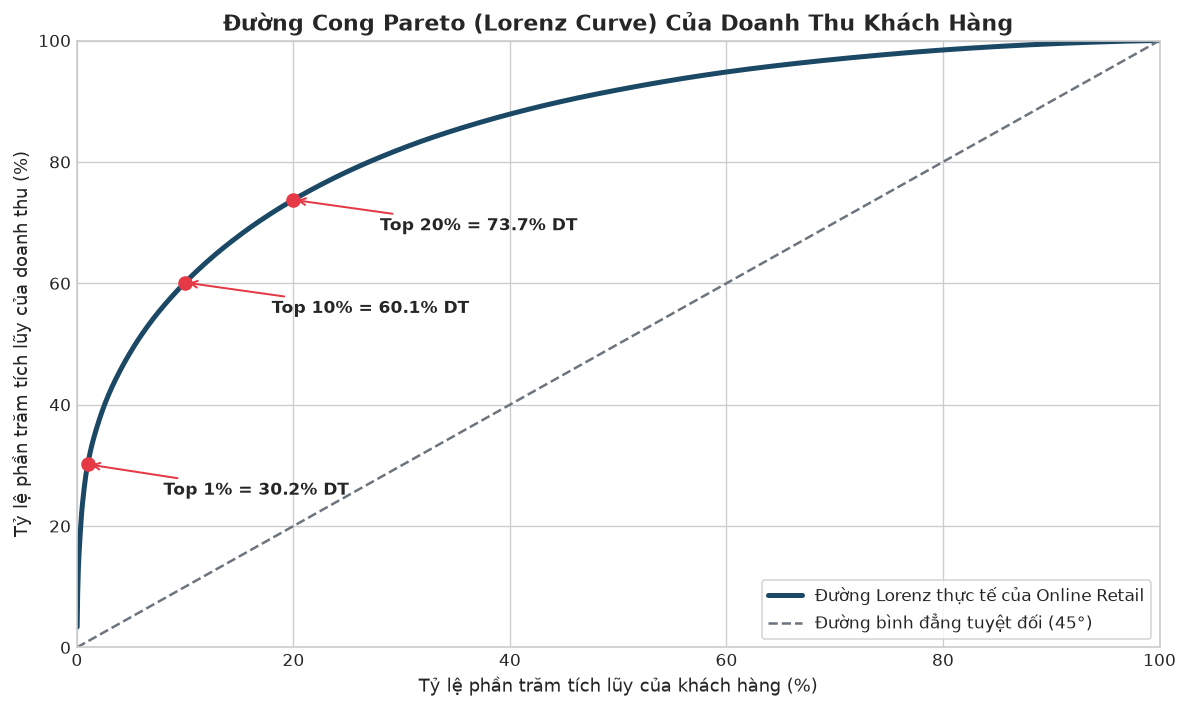

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))

# Vẽ đường Lorenz thực tế
ax.plot(active_df["CumCustPct"], active_df["CumSpendPct"], color="#1b4965", linewidth=3, label="Đường Lorenz thực tế của Online Retail")

# Vẽ đường phân bổ đều lý thuyết (Line of Equality)
ax.plot([0, 100], [0, 100], color="#6c757d", linestyle="--", linewidth=1.5, label="Đường bình đẳng tuyệt đối (45°)")

# Đánh dấu các mốc quan trọng
ax.scatter([1, 10, 20], [pct_1, pct_10, pct_20], color="#e63946", s=60, zorder=5)
ax.annotate(f"Top 1% = {pct_1:.1f}% DT", xy=(1, pct_1), xytext=(8, pct_1 - 5),
            arrowprops=dict(arrowstyle="->", color="#e63946", lw=1.2), fontweight="bold")
ax.annotate(f"Top 10% = {pct_10:.1f}% DT", xy=(10, pct_10), xytext=(18, pct_10 - 5),
            arrowprops=dict(arrowstyle="->", color="#e63946", lw=1.2), fontweight="bold")
ax.annotate(f"Top 20% = {pct_20:.1f}% DT", xy=(20, pct_20), xytext=(28, pct_20 - 5),
            arrowprops=dict(arrowstyle="->", color="#e63946", lw=1.2), fontweight="bold")

ax.set_title("Đường Cong Pareto (Lorenz Curve) Của Doanh Thu Khách Hàng", fontsize=13, fontweight="bold")
ax.set_xlabel("Tỷ lệ phần trăm tích lũy của khách hàng (%)", fontsize=11)
ax.set_ylabel("Tỷ lệ phần trăm tích lũy của doanh thu (%)", fontsize=11)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()


## 2. Chiến Lược Tương Tác Theo Phân Khúc (Actionable CRM Playbook)
Mỗi phân khúc khách hàng đại diện cho một vị thế tài chính và rủi ro khác nhau. Thay vì áp dụng chính sách khuyến mãi đại trà làm xói mòn biên lợi nhuận, doanh nghiệp cần phân bổ nguồn lực dựa trên ma trận hành vi:


In [4]:
crm_data = [
    {
        "Phân khúc": "Champions",
        "Quy mô": "1.023 (23,6%)",
        "Tỷ trọng DT": "66,9%",
        "Mục tiêu cốt lõi": "Bảo vệ tối đa doanh thu; giữ chân bằng dịch vụ đặc quyền",
        "Kênh tương tác": "Key Account Manager (Sales chuyên trách) + Điện thoại trực tiếp",
        "Chính sách ưu đãi": "Chiết khấu theo doanh số năm (Annual Volume Rebates), ưu tiên kho vận mùa Q4",
        "KPI then chốt": "Tỷ lệ giữ chân năm > 85%; Net Expansion Revenue"
    },
    {
        "Phân khúc": "Loyal Customers",
        "Quy mô": "470 (10,9%)",
        "Tỷ trọng DT": "11,2%",
        "Mục tiêu cốt lõi": "Nâng hạng lên Champions; gia tăng danh mục sản phẩm (Cross-sell)",
        "Kênh tương tác": "Email cá nhân hóa + Tư vấn viên định kỳ",
        "Chính sách ưu đãi": "Chương trình nâng hạng VIP; chiết khấu khi mua danh mục sản phẩm mới",
        "KPI then chốt": "Tần suất đặt hàng tăng từ F=4 lên F>=6; Tỷ lệ mua chéo danh mục"
    },
    {
        "Phân khúc": "Potential Loyalists",
        "Quy mô": "400 (9,2%)",
        "Tỷ trọng DT": "3,6%",
        "Mục tiêu cốt lõi": "Kích thích đơn hàng thứ 3 và thứ 4; thiết lập thói quen đặt hàng định kỳ",
        "Kênh tương tác": "Email tự động theo chu kỳ + Remarketing",
        "Chính sách ưu đãi": "Miễn phí vận chuyển cho đơn hàng lớn tiếp theo; gợi ý mặt hàng bổ trợ",
        "KPI then chốt": "Tỷ lệ chuyển đổi đơn thứ 3 trong 45 ngày"
    },
    {
        "Phân khúc": "Promising",
        "Quy mô": "475 (11,0%)",
        "Tỷ trọng DT": "2,9%",
        "Mục tiêu cốt lõi": "Cầu nối sống còn: Ngăn chặn rơi vào ngủ đông (R=32-71 ngày, F=1-2)",
        "Kênh tương tác": "Email chuỗi tương tác (Nurture Sequence) + Thông báo đẩy",
        "Chính sách ưu đãi": "Voucher ngắn hạn (14 ngày) kèm ngưỡng đơn hàng tối thiểu (MOQ threshold)",
        "KPI then chốt": "Tỷ lệ tái mua đơn 2/đơn 3 trong 30 ngày can thiệp"
    },
    {
        "Phân khúc": "New Customers",
        "Quy mô": "236 (5,5%)",
        "Tỷ trọng DT": "0,9%",
        "Mục tiêu cốt lõi": "Hòa nhập nhanh (Onboarding); biến đơn hàng đầu tiên thành quan hệ dài hạn",
        "Kênh tương tác": "Email chào mừng 3 bước (Welcome Series) + Hỗ trợ kích hoạt tài khoản",
        "Chính sách ưu đãi": "Tài liệu giới thiệu sản phẩm bán sỉ chạy nhất (B2B Best-sellers) + Hỗ trợ mẫu thử",
        "KPI then chốt": "Tỷ lệ tái mua trong 60 ngày đầu tiên (mục tiêu > 35%)"
    },
    {
        "Phân khúc": "Need Attention",
        "Quy mô": "301 (7,0%)",
        "Tỷ trọng DT": "5,5%",
        "Mục tiêu cốt lõi": "Tái kích hoạt khẩn cấp: Khách mua nhiều (F=3-6+) nhưng đã 2,5-6 tháng không mua",
        "Kênh tương tác": "Cuộc gọi từ bộ phận Chăm sóc khách hàng hoặc Khảo sát sự hài lòng",
        "Chính sách ưu đãi": "Gói ưu đãi đặc biệt We miss you; chính sách giá độc quyền cho mặt hàng quen thuộc",
        "KPI then chốt": "Tỷ lệ phản hồi khảo sát; Tỷ lệ quay lại mua hàng trong 30 ngày"
    },
    {
        "Phân khúc": "About to Sleep",
        "Quy mô": "558 (12,9%)",
        "Tỷ trọng DT": "3,6%",
        "Mục tiêu cốt lõi": "Đánh thức trước khi thành Lost: Khách mua ít (F=1-2) sắp mất dấu",
        "Kênh tương tác": "Chiến dịch Email kích hoạt tự động với dòng tiêu đề thu hút",
        "Chính sách ưu đãi": "Khuyến mãi có thời hạn (Flash discount) để kích hoạt giao dịch",
        "KPI then chốt": "Tỷ lệ mở email (Open rate) > 25%; Tỷ lệ click-through > 5%"
    },
    {
        "Phân khúc": "At Risk",
        "Quy mô": "83 (1,9%)",
        "Tỷ trọng DT": "1,9%",
        "Mục tiêu cốt lõi": "Cứu vãn khách hàng sỉ từng chi tiêu lớn đã ngừng mua trên 6 tháng",
        "Kênh tương tác": "Sales Manager cấp cao liên hệ trực tiếp; khảo sát lý do chuyển nhà cung cấp",
        "Chính sách ưu đãi": "Đàm phán lại hợp đồng khung; chính sách công nợ linh hoạt hơn nếu thanh toán tốt",
        "KPI then chốt": "Số lượng tài khoản sỉ được kích hoạt lại (Reactivation Rate)"
    },
    {
        "Phân khúc": "Hibernating",
        "Quy mô": "157 (3,6%)",
        "Tỷ trọng DT": "1,1%",
        "Mục tiêu cốt lõi": "Nuôi dưỡng chi phí thấp; duy trì nhận diện thương hiệu",
        "Kênh tương tác": "Bản tin tổng hợp sản phẩm mới theo quý (Quarterly Catalog)",
        "Chính sách ưu đãi": "Thông báo giảm giá khi thanh lý tồn kho (Clearance sales)",
        "KPI then chốt": "Chi phí tiếp thị trên mỗi lượt chuyển đổi (CPA thấp)"
    },
    {
        "Phân khúc": "Lost",
        "Quy mô": "621 (14,4%)",
        "Tỷ trọng DT": "2,4%",
        "Mục tiêu cốt lõi": "Ngừng chi tiêu tiếp thị trực tiếp; chỉ gửi chiến dịch tự động diện rộng",
        "Kênh tương tác": "Email thanh lý hàng tồn định kỳ hàng quý",
        "Chính sách ưu đãi": "Xả hàng cuối năm (Year-end liquidation)",
        "KPI then chốt": "Doanh thu thu hồi từ tài khoản đã chết"
    },
    {
        "Phân khúc": "Zero Net Spend",
        "Quy mô": "10 (0,2%)",
        "Tỷ trọng DT": "0,0%",
        "Mục tiêu cốt lõi": "Kiểm tra kỹ thuật & Chống gian lận; không áp dụng chiến dịch kích hoạt",
        "Kênh tương tác": "Đội ngũ Vận hành kho & Kế toán rà soát đơn hàng",
        "Chính sách ưu đãi": "Yêu cầu thanh toán trước 100% đối với các đơn hàng giá trị lớn tiếp theo",
        "KPI then chốt": "Tỷ lệ hoàn trả khớp gốc của tài khoản mới"
    }
]

df_crm = pd.DataFrame(crm_data)
print("--- KHUNG KẾ HOẠCH HÀNH ĐỘNG CRM THEO PHÂN KHÚC (ACTIONABLE CRM PLAYBOOK) ---")
display(df_crm[["Phân khúc", "Quy mô", "Tỷ trọng DT", "Mục tiêu cốt lõi", "Chính sách ưu đãi", "KPI then chốt"]])


--- KHUNG KẾ HOẠCH HÀNH ĐỘNG CRM THEO PHÂN KHÚC (ACTIONABLE CRM PLAYBOOK) ---


,Phân khúc,Quy mô,Tỷ trọng DT,Mục tiêu cốt lõi,Chính sách ưu đãi,KPI then chốt
0,Champions,"1.023 (23,6%)","66,9%",Bảo vệ tối đa doanh thu; giữ chân bằng dịch vụ...,Chiết khấu theo doanh số năm (Annual Volume Re...,Tỷ lệ giữ chân năm > 85%; Net Expansion Revenue
1,Loyal Customers,"470 (10,9%)","11,2%",Nâng hạng lên Champions; gia tăng danh mục sản...,Chương trình nâng hạng VIP; chiết khấu khi mua...,Tần suất đặt hàng tăng từ F=4 lên F>=6; Tỷ lệ ...
2,Potential Loyalists,"400 (9,2%)","3,6%",Kích thích đơn hàng thứ 3 và thứ 4; thiết lập ...,Miễn phí vận chuyển cho đơn hàng lớn tiếp theo...,Tỷ lệ chuyển đổi đơn thứ 3 trong 45 ngày
3,Promising,"475 (11,0%)","2,9%",Cầu nối sống còn: Ngăn chặn rơi vào ngủ đông (...,Voucher ngắn hạn (14 ngày) kèm ngưỡng đơn hàng...,Tỷ lệ tái mua đơn 2/đơn 3 trong 30 ngày can thiệp
4,New Customers,"236 (5,5%)","0,9%",Hòa nhập nhanh (Onboarding); biến đơn hàng đầu...,Tài liệu giới thiệu sản phẩm bán sỉ chạy nhất ...,Tỷ lệ tái mua trong 60 ngày đầu tiên (mục tiêu...
5,Need Attention,"301 (7,0%)","5,5%",Tái kích hoạt khẩn cấp: Khách mua nhiều (F=3-6...,Gói ưu đãi đặc biệt We miss you; chính sách gi...,Tỷ lệ phản hồi khảo sát; Tỷ lệ quay lại mua hà...
6,About to Sleep,"558 (12,9%)","3,6%",Đánh thức trước khi thành Lost: Khách mua ít (...,Khuyến mãi có thời hạn (Flash discount) để kíc...,Tỷ lệ mở email (Open rate) > 25%; Tỷ lệ click-...
7,At Risk,"83 (1,9%)","1,9%",Cứu vãn khách hàng sỉ từng chi tiêu lớn đã ngừ...,Đàm phán lại hợp đồng khung; chính sách công n...,Số lượng tài khoản sỉ được kích hoạt lại (Reac...
8,Hibernating,"157 (3,6%)","1,1%",Nuôi dưỡng chi phí thấp; duy trì nhận diện thư...,Thông báo giảm giá khi thanh lý tồn kho (Clear...,Chi phí tiếp thị trên mỗi lượt chuyển đổi (CPA...
9,Lost,"621 (14,4%)","2,4%",Ngừng chi tiêu tiếp thị trực tiếp; chỉ gửi chi...,Xả hàng cuối năm (Year-end liquidation),Doanh thu thu hồi từ tài khoản đã chết


## 3. Thiết Kế Khung Thử Nghiệm A/B Testing Can Thiệp (Holdout Testing)

### 3.1. Căn Cứ Thống Kê Từ Phân Tích Cohort
1. **Xác suất mua lại nền phẳng (Flat Forward Hazard):** Trong cửa sổ tiến 30 ngày, tỷ lệ khách hàng tự mua lại dao động phẳng từ **14,6% đến 18,0%**, không có điểm rơi đột ngột quanh ngày 70–80.
2. **Rủi ro Cannibalization thấp:** Vì mã ưu đãi chỉ có thời hạn ngắn (14–30 ngày), chỉ có khoảng 15%–18% khách hàng tự mua lại trong thời gian đó. Nghĩa là **82%–85% khách hàng chưa mua lại sẽ KHÔNG tự phát sinh giao dịch**.
3. **Cần đo lường Incremental Lift:** Doanh nghiệp không thể suy diễn ngày tối ưu chỉ từ dữ liệu lịch sử thụ động, mà phải đo lường bằng thử nghiệm can thiệp thực tế có đối chứng.

### 3.2. Cấu Trúc Thử Nghiệm 3 Nhánh (Randomized Controlled Trial - RCT)
* **Tập mẫu:** Khách hàng mới thuần túy sau đơn hàng đầu tiên chưa có đơn thứ 2.
* **Nhánh A (Can thiệp sớm):** Kích hoạt vào **Ngày 45** (khi ~74,7% khách chưa mua lại).
* **Nhánh B (Can thiệp muộn):** Kích hoạt vào **Ngày 75** (khi ~61,8% khách chưa mua lại).
* **Nhánh C (Nhóm đối chứng - Holdout Group):** Giữ lại **15% – 20%** khách hàng ngẫu nhiên **hoàn toàn không nhận voucher** để đo baseline mua lại tự nhiên.

Dưới đây ta mô phỏng tính toán kích thước mẫu (Sample Size & Statistical Power) cần thiết:


In [5]:
# Tính toán kích thước mẫu cần thiết cho thử nghiệm A/B
# Giả định tỷ lệ baseline tự nhiên p0 = 16.5% trong cửa sổ 30 ngày
# Kỳ vọng mức tăng thêm tối thiểu có ý nghĩa kinh doanh (Minimum Detectable Effect - MDE) = +4.0 điểm % (lên 20.5%)
p0 = 0.165
p1 = 0.205
alpha = 0.05
power = 0.80

z_alpha = stats.norm.ppf(1 - alpha / 2) # 1.96
z_beta = stats.norm.ppf(power)          # 0.84

p_pooled = (p0 + p1) / 2
numerator = (z_alpha * np.sqrt(2 * p_pooled * (1 - p_pooled)) + z_beta * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2
sample_size_per_arm = numerator / ((p1 - p0) ** 2)

print("--- THIẾT KẾ THỰC NGHIỆM A/B TESTING ---")
print(f"Tỷ lệ mua lại nền tự nhiên (Baseline Conversion p0): {p0:.1%}")
print(f"Mức chuyển đổi kỳ vọng sau can thiệp (Target Conversion p1): {p1:.1%}")
print(f"Hiệu ứng tối thiểu cần phát hiện (MDE): +{(p1 - p0):.1%}")
print(f"Kích thước mẫu tối thiểu mỗi nhánh (Alpha=5%, Power=80%): {int(np.ceil(sample_size_per_arm)):,} khách hàng/nhánh")

# So sánh với dòng khách hàng mới thực tế của doanh nghiệp:
# 3,719 khách mới/năm -> ~2,780 khách đủ điều kiện chưa mua tại Ngày 45
annual_eligible = 3719 * 0.747
print(f"Số lượng khách hàng đủ điều kiện tiếp cận mỗi năm (tại Ngày 45): ~{int(annual_eligible):,} khách")
print(f"Thời gian chạy thử nghiệm để đạt đủ mẫu thống kê: ~{sample_size_per_arm * 3 / annual_eligible * 12:.1f} tháng (với 3 nhánh A/B/Holdout)")


--- THIẾT KẾ THỰC NGHIỆM A/B TESTING ---
Tỷ lệ mua lại nền tự nhiên (Baseline Conversion p0): 16.5%
Mức chuyển đổi kỳ vọng sau can thiệp (Target Conversion p1): 20.5%
Hiệu ứng tối thiểu cần phát hiện (MDE): +4.0%
Kích thước mẫu tối thiểu mỗi nhánh (Alpha=5%, Power=80%): 1,479 khách hàng/nhánh
Số lượng khách hàng đủ điều kiện tiếp cận mỗi năm (tại Ngày 45): ~2,778 khách
Thời gian chạy thử nghiệm để đạt đủ mẫu thống kê: ~19.2 tháng (với 3 nhánh A/B/Holdout)


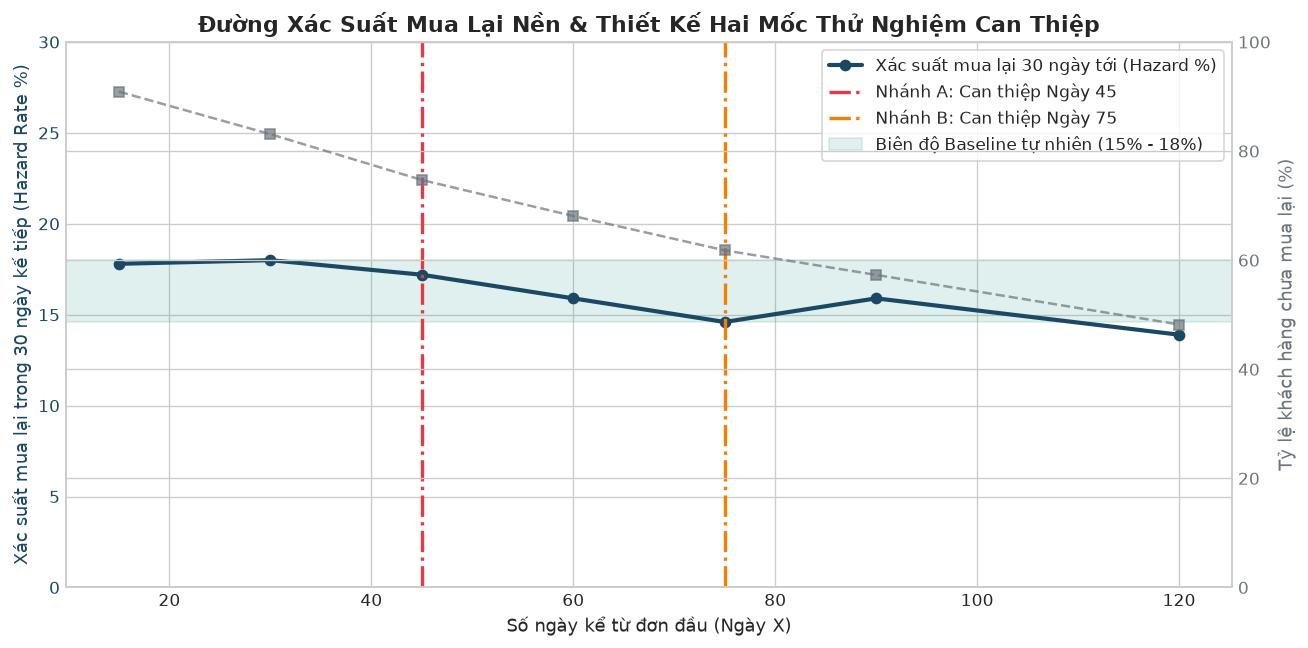

In [6]:
# Trực quan hóa đường Hazard và hai mốc can thiệp A/B
days = [15, 30, 45, 60, 75, 90, 120]
hazards = [17.8, 18.0, 17.2, 15.9, 14.6, 15.9, 13.9]
unrep_pcts = [90.9, 83.1, 74.7, 68.1, 61.8, 57.3, 48.2]

fig, ax1 = plt.subplots(figsize=(11, 5.5))

color = "#1b4965"
ax1.set_xlabel("Số ngày kể từ đơn đầu (Ngày X)", fontsize=11)
ax1.set_ylabel("Xác suất mua lại trong 30 ngày kế tiếp (Hazard Rate %)", color=color, fontsize=11)
line1 = ax1.plot(days, hazards, color=color, marker="o", linewidth=2.5, label="Xác suất mua lại 30 ngày tới (Hazard %)")
ax1.tick_params(axis="y", labelcolor=color)
ax1.set_ylim(0, 30)

# Trục thứ 2: Tỷ lệ khách chưa mua lại
ax2 = ax1.twinx()
color2 = "#6c757d"
ax2.set_ylabel("Tỷ lệ khách hàng chưa mua lại (%)", color=color2, fontsize=11)
line2 = ax2.plot(days, unrep_pcts, color=color2, marker="s", linestyle="--", linewidth=1.5, alpha=0.7, label="% Khách chưa mua lại")
ax2.tick_params(axis="y", labelcolor=color2)
ax2.set_ylim(0, 100)

# Đánh dấu 2 điểm can thiệp đề xuất
ax1.axvline(45, color="#e63946", linestyle="-.", linewidth=2, label="Nhánh A: Can thiệp Ngày 45")
ax1.axvline(75, color="#f77f00", linestyle="-.", linewidth=2, label="Nhánh B: Can thiệp Ngày 75")

# Ghi chú vùng Holdout Baseline
ax1.axhspan(14.6, 18.0, color="#2a9d8f", alpha=0.15, label="Biên độ Baseline tự nhiên (15% - 18%)")

# Gộp chú thích
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(loc="upper right", frameon=True)

plt.title("Đường Xác Suất Mua Lại Nền & Thiết Kế Hai Mốc Thử Nghiệm Can Thiệp", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Mô Hình Hóa Tác Động Doanh Thu & Tài Chính (Financial Impact Model)

### 4.1. Cơ Sở Tính Toán Doanh Thu Tháng 1
* **Quy mô khách mới:** 11 cohort khách mới năm 2011 mang về 3.409 khách hàng, tương đương tốc độ thu hút:
  $$\text{Khách mới quy năm} = \frac{3.409}{11} \times 12 \approx 3.718,9 \text{ khách/năm}$$
* **Doanh thu trung bình trên khách hoạt động Tháng 1 (Pooled RPA Month 1):**
  $$\text{Pooled RPA Month 1} = \frac{£268.262,24}{609} \approx \mathbf{£440,50}$$
* **Giả định then chốt:** Đây là doanh thu gộp tăng thêm phát sinh **ngay trong Tháng 1 đầu tiên** sau can thiệp, với giả định nhóm khách hàng được giữ lại thêm có mức chi tiêu tương đương mức trung bình Tháng 1 (£440,50).

Dưới đây ta xây dựng bảng phân tích độ nhạy (Sensitivity Analysis) với các kịch bản cải thiện tỷ lệ giữ chân từ +1.0 đến +5.0 điểm phần trăm:


In [7]:
annual_new_cust = (3409 / 11) * 12
rpa_m1 = 440.50
gross_margin_rate = 0.28 # Giả định biên lợi nhuận gộp B2B chuẩn là 28%

scenarios = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
impact_rows = []

for lift in scenarios:
    added_custs = annual_new_cust * (lift / 100)
    incremental_rev = added_custs * rpa_m1
    incremental_gross_profit = incremental_rev * gross_margin_rate
    
    impact_rows.append({
        "Mức cải thiện Retention Tháng 1 (+điểm %)": f"+{lift:.1f}%",
        "Số khách giữ lại thêm mỗi năm": f"{added_custs:.1f} khách",
        "Doanh thu gộp tăng thêm Tháng 1 (Gross)": f"£{incremental_rev:,.2f}",
        "Lợi nhuận gộp tăng thêm Tháng 1 (Margin 28%)": f"£{incremental_gross_profit:,.2f}",
        "Giá trị vòng đời LTV ước tính (Hệ số 2.5x)": f"£{incremental_rev * 2.5:,.2f}"
    })

df_impact = pd.DataFrame(impact_rows)
print("--- BẢNG PHÂN TÍCH ĐỘ NHẠY TÁC ĐỘNG TÀI CHÍNH KHI NÂNG CAO TỶ LỆ GIỮ CHÂN ---")
display(df_impact)


--- BẢNG PHÂN TÍCH ĐỘ NHẠY TÁC ĐỘNG TÀI CHÍNH KHI NÂNG CAO TỶ LỆ GIỮ CHÂN ---


,Mức cải thiện Retention Tháng 1 (+điểm %),Số khách giữ lại thêm mỗi năm,Doanh thu gộp tăng thêm Tháng 1 (Gross),Lợi nhuận gộp tăng thêm Tháng 1 (Margin 28%),Giá trị vòng đời LTV ước tính (Hệ số 2.5x)
0,+1.0%,37.2 khách,"£16,381.79","£4,586.90","£40,954.49"
1,+1.5%,55.8 khách,"£24,572.69","£6,880.35","£61,431.73"
2,+2.0%,74.4 khách,"£32,763.59","£9,173.80","£81,908.97"
3,+2.5%,93.0 khách,"£40,954.49","£11,467.26","£102,386.22"
4,+3.0%,111.6 khách,"£49,145.38","£13,760.71","£122,863.46"
5,+4.0%,148.8 khách,"£65,527.18","£18,347.61","£163,817.95"
6,+5.0%,185.9 khách,"£81,908.97","£22,934.51","£204,772.43"


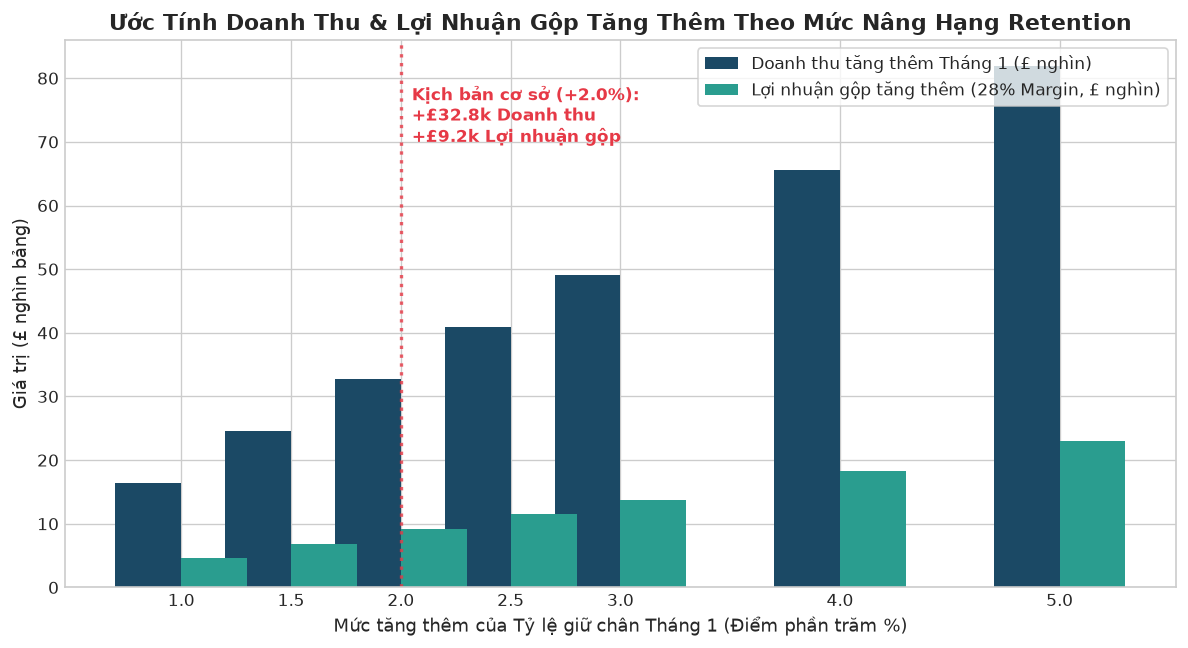

In [8]:
lifts = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
rev_impacts = [annual_new_cust * (l / 100) * rpa_m1 for l in lifts]
profit_impacts = [r * gross_margin_rate for r in rev_impacts]

fig, ax = plt.subplots(figsize=(10, 5.5))
bar1 = ax.bar([x - 0.15 for x in lifts], [r / 1000 for r in rev_impacts], width=0.3, label="Doanh thu tăng thêm Tháng 1 (£ nghìn)", color="#1b4965")
bar2 = ax.bar([x + 0.15 for x in lifts], [p / 1000 for p in profit_impacts], width=0.3, label="Lợi nhuận gộp tăng thêm (28% Margin, £ nghìn)", color="#2a9d8f")

ax.set_title("Ước Tính Doanh Thu & Lợi Nhuận Gộp Tăng Thêm Theo Mức Nâng Hạng Retention", fontsize=13, fontweight="bold")
ax.set_xlabel("Mức tăng thêm của Tỷ lệ giữ chân Tháng 1 (Điểm phần trăm %)", fontsize=11)
ax.set_ylabel("Giá trị (£ nghìn bảng)", fontsize=11)
ax.set_xticks(lifts)
ax.legend(frameon=True)

# Đánh dấu kịch bản mục tiêu +2.0 điểm %
ax.axvline(2.0, color="#e63946", linestyle=":", linewidth=2, alpha=0.8)
ax.text(2.05, 70, "Kịch bản cơ sở (+2.0%):\n+£32.8k Doanh thu\n+£9.2k Lợi nhuận gộp", fontsize=10, fontweight="bold", color="#e63946")

plt.tight_layout()
plt.show()


## 5. Khuyến Nghị Chiến Lược Dài Hạn Cho Mô Hình B2B Wholesale

### 5.1. Quản Trị Khách Hàng Trọng Điểm (Key Account Management - KAM)
* **Thực trạng:** Nhóm Champions chiếm tới 66,9% doanh thu toàn công ty. Việc mất đi chỉ 5–10 khách hàng lớn có thể làm sụt giảm ngay lập tức 5% tổng doanh số.
* **Hành động:** Thiết lập chương trình chăm sóc khách hàng VIP riêng biệt:
  * Phân bổ chuyên viên quản lý tài khoản riêng (Dedicated KAM) cho Top 100 khách hàng lớn nhất.
  * Hợp đồng khung hàng năm cam kết hạn ngạch và chiết khấu hồi tố theo bậc sản lượng (Annual Volume Rebates).
  * Ưu tiên phân bổ đơn hàng trong thời kỳ kho vận căng thẳng ở Quý 4.

### 5.2. Chính Sách Chiết Khấu Bậc Thang (Volume Discount Tiers)
* **Thực trạng:** Các cohort khách mới có giá trị chi tiêu mỗi khách (RPA) không tự động mở rộng theo thời gian mà chỉ đi ngang quanh 100%.
* **Hành động:** Thay vì giảm giá phần trăm trực tiếp trên toàn bộ đơn, doanh nghiệp nên áp dụng mức sàn số lượng đặt hàng tối thiểu (MOQ) và chiết khấu lũy tiến:
  * Bậc 1 (Đơn chuẩn): Giá niêm yết (List price).
  * Bậc 2 (Đơn $> £500$): Chiết khấu 3% hoặc miễn cước vận chuyển.
  * Bậc 3 (Đơn $> £1.500$): Chiết khấu 7% kèm thời hạn thanh toán linh hoạt 30 ngày (Net 30 terms).

### 5.3. Chiến Dịch Đặt Hàng Sớm Mùa Lễ Hội (Q4 Early Bird Ordering Hypothesis)
* **Thực trạng:** Phân tích Cohort ở Notebook 02 cho thấy doanh số tháng 9 đến tháng 11 tăng vọt gấp 2–3 lần bình thường (£1.00M – £1.14M/tháng) do khách sỉ tích trữ hàng hóa phục vụ mùa Giáng sinh. Sự đột biến này gây áp lực nghẽn kho vận và thiếu hụt hàng hóa.
* **Hành động:** 
  * Phát động chiến dịch "Early Bird Christmas Booking" ngay từ **Tháng 8 và đầu Tháng 9**.
  * Dành mức ưu đãi giá tốt nhất cho các nhà bán lẻ cam kết đặt cọc sớm trước 15/09, giúp san phẳng tải trọng vận hành kho và giữ chân khách hàng sớm trước khi các đối thủ kịp tung chương trình mùa vụ.
